# 🤗 Hugging Face 생태계 쿡북

> **Hugging Face Hub와 라이브러리를 코드로 직접 돌려봅니다.**

- **소개**: **Hugging Face Hub란 무엇인지**부터 시작해, Hugging Face 라이브러리와 서비스가 어떻게 구성되는지 확인합니다. Hugging Face 라이브러리를 쓴 프로젝트 사례도 직접 살펴봅니다.

| 챕터 | 내용 |
|---|---|
| 1 | Hugging Face Hub란? — 공식 정의부터 |
| 2 | 라이브러리 레시피 — 기반 / 학습 / 서빙·출구 |
| 3 | 번역 MCP server 프로젝트 |
| 4 | OCR + chat with paper 프로젝트 |
| 5 | AWS와의 공통점 |
| 6 | DEMO |

---
## 0. 준비 — 설치

이 쿡북의 레시피는 대부분 `huggingface_hub`, `transformers`, `datasets`, `gradio`, `peft`, `accelerate`면 충분합니다. 아래 셀을 실행하면 설치됩니다. 공개 모델·데이터셋 위주는 로그인 없이 실행할 수 있지만, Inference Providers 셀은 토큰 로그인이 필요합니다. 해당 셀 첫 줄의 `notebook_login()`으로 로그인하세요.

In [ ]:
!pip install -q huggingface_hub transformers datasets gradio accelerate peft
from huggingface_hub import HfApi
api = HfApi()
print("연결 OK — Hub에서 모델을 검색할 준비가 됐습니다.")

---
## 1. Hugging Face Hub란?

이 장에서는 Hub의 공식 정의부터 확인합니다. Hugging Face의 LLM Course가 이렇게 정의합니다.

> "The Hugging Face Hub – our main website – is a central platform that enables anyone to discover, use, and contribute new state-of-the-art models and datasets."
>
> 출처: [Hugging Face LLM Course, Chapter 4.1 "The Hugging Face Hub"](https://huggingface.co/learn/llm-course/en/chapter4/1)

한국어로 옮기면: **"Hugging Face Hub(우리의 메인 웹사이트)는 누구나 최신 모델과 데이터셋을 발견하고, 사용하고, 기여할 수 있는 중앙 플랫폼입니다."**

- **Hub 바로 가기**: [https://huggingface.co/](https://huggingface.co/)
- **여기에 모이는 것**: 모델 · 데이터셋 · Spaces(데모 앱). 각 모델은 Git 저장소처럼 올라가 있어 버전 관리와 재현이 됩니다. 그래서 이 쿡북의 주제가 "GitHub for ML"입니다.
- **이 쿡북에서의 위치**: 다음 장(2장)의 라이브러리들은 전부 이 Hub에서 내려받고 여기로 올리는 도구들입니다. Hub가 광장이면, 라이브러리는 그 광장을 쓰는 방법입니다.

> 💡 Hub에는 **논문 페이지**도 있습니다. 4장 OCR + chat with paper(읽기)에서 설명합니다.

In [ ]:
# Hub에서 모델 찾아보기 — 'Hub란?'을 코드로 (4장에서 쓸 OCR 모델을 미리 검색해 봅니다)
for m in api.list_models(search="chandra-ocr", limit=3):
    print(m.id)

datalab-to/chandra-ocr-2


---
## 2. 라이브러리 레시피 — 기반 / 학습 / 서빙·출구

라이브러리를 용도별 세 그룹으로 정리한 챕터입니다.

### 2.1. 기반 — 모든 것의 토대

| 라이브러리 | 한 줄 역할 |
|---|---|
| **Hub (`huggingface_hub`)** | 모델·데이터셋·Space가 올라가는 저장소이자 API. 각 모델과 데이터셋은 Git 저장소로 버전 관리되고, ID와 버전으로 찍어 내려받는다 |
| **`transformers`** | 모델을 불러와 추론·학습하는 표준 라이브러리 |
| **`datasets`** | 데이터셋을 한 줄로 내려받고 전처리하는 라이브러리 |
| **`tokenizers`** | 텍스트를 모델 입력 숫자로 바꾸는 빠른 토크나이저 |

In [ ]:
# transformers — pipeline 한 줄로 감성 분석
from transformers import pipeline
clf = pipeline("sentiment-analysis")
print(clf("Hugging Face makes ML feel like Lego."))

[{'label': 'POSITIVE', 'score': 0.999}]  # (예시 출력)


In [ ]:
# datasets — 데이터셋 한 줄 로드 (이름공간까지 쓴 정식 ID)
from datasets import load_dataset
ds = load_dataset("stanfordnlp/imdb", split="train[:3]")
print(ds)
print(ds[0]["text"][:60], "...")

Dataset({
    features: ['text', 'label'],
    num_rows: 3
})
I rented I AM CURIOUS-YELLOW from my video store because of  ...


In [ ]:
# tokenizers — 텍스트가 숫자가 되는 순간
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("bert-base-uncased")
print(tok("Hugging Face is open source!")["input_ids"])

[101, 17662, 2227, 2003, 2898, 4524, 999, 102]  # (예시 출력 — 실제 값은 실행해 확인)


### 2.2. 학습 — 만들 때 쓰는 도구

| 라이브러리 | 한 줄 역할 |
|---|---|
| **diffusers** | Stable Diffusion 같은 확산 모델의 표준 라이브러리. 파이프라인과 스케줄러를 분리해 조합 |
| **accelerate** | PyTorch 학습 루프 위에 분산 설정을 얹는 도구 |
| **PEFT** | transformers 모델에 LoRA 같은 어댑터를 붙이는 기법 모음. **QLoRA**는 양자화된 베이스 모델 위에 LoRA를 얹는 변형 |
| **TRL** | SFT·RLHF·DPO 같은 정렬(후학습) 레시피를 Trainer로 제공하는 라이브러리 |
| **optimum** | 모델을 ONNX·OpenVINO·TensorRT용으로 최적화해 내보내는 도구 |
| **safetensors** | pickle의 보안 문제를 없앤 가중치 포맷. 빠른 로딩과 안전한 공유가 기본값 |

In [ ]:
# PEFT — LoRA 설정만으로 파인튜닝 준비 끝 (학습은 실행하지 않고, 설정 형태만 확인합니다)
from peft import LoraConfig
cfg = LoraConfig(r=8, lora_alpha=16, target_modules=["q_proj", "v_proj"], task_type="CAUSAL_LM")
print(cfg)
print("→ 전체를 다 학습하지 않고 작은 어댑터만 학습합니다. TRL의 SFTTrainer에 이 설정을 얹으면 SFT가 됩니다.")

LoraConfig(r=8, lora_alpha=16, target_modules=['q_proj', 'v_proj'], ...)
→ 전체를 다 학습하지 않고 작은 어댑터만 학습합니다.


### 2.3. 서빙·출구 — 만든 것을 세상에 내보내는 곳

| 도구 | 한 줄 역할 |
|---|---|
| **Gradio** | 파이썬 몇 줄로 데모 UI를 만드는 라이브러리 |
| **Spaces** | 데모 앱 호스팅 — AWS로 치면 Amplify / App Runner |
| **Inference Providers** | 여러 제공자의 모델을 하나의 API로 호출 — AWS로 치면 Bedrock 같은 통합 API |
| **Inference Endpoints** | 모델 전용 추론 엔드포인트 |
| **TEI** | 임베딩 전용 서빙 엔진 |
| **TGI** | LLM 서빙 엔진 |
| **Jobs** | GPU 작업을 제출하면 돌리고 꺼지는 서버리스 컴퓨트 (4장의 주인공) |
| **smolagents** | 가벼운 에이전트 프레임워크 |
| **HuggingChat** | 오픈 모델을 바로 써보는 채팅 플랫폼 |

In [ ]:
# Inference Providers — InferenceClient 한 줄 호출 (provider만 바꾸면 제공자가 바뀐다)
from huggingface_hub import InferenceClient, notebook_login
notebook_login()  # Inference Providers는 토큰 로그인이 필요합니다
client = InferenceClient(provider="deepinfra")
answer = client.chat_completion(
    [{"role": "user", "content": "Hugging Face를 한 문장으로 설명해줘"}],
    model="Qwen/Qwen3-235B-A22B-Instruct-2507", max_tokens=60,
)
print(answer.choices[0].message.content)

Hugging Face는 전 세계 개발자가 AI 모델과 데이터셋을 공유하고 바로 써볼 수 있는 오픈 플랫폼입니다.  # (예시 출력)


In [ ]:
# Gradio — 5줄 데모. 이 코드가 그대로 Space가 됩니다.
import gradio as gr

def greet(name):
    return f"안녕하세요, {name}님! 이게 Gradio 데모입니다."

gr.Interface(fn=greet, inputs="text", outputs="text").launch()

Running on local URL:  http://127.0.0.1:7860  # (예시 출력)


### 🔗 더 보기 — Gradio 데모

**Gradio 데모**를 직접 실행해 볼 수 있는 Space입니다. 프롬프트에 `a tiny astronaut hatching from an egg on the moon`를 넣으면 이미지 생성 데모를 실행해 볼 수 있습니다.

- Gradio 데모 Space (FLUX.1-schnell): https://huggingface.co/spaces/black-forest-labs/FLUX.1-schnell

---
## 3. 번역 MCP server 프로젝트

**공개 프로젝트**입니다. GitHub: [https://github.com/Hugging-Face-KREW/hf_translation_hub](https://github.com/Hugging-Face-KREW/hf_translation_hub)

아키텍처 구조는 다음과 같습니다.

```
외부 에이전트 (조합·오케스트레이션)
        │  필요할 때 도구를 골라 호출
        ├─→ 문서 탐색 도구      (Gradio MCP)
        ├─→ 번역 지원 도구      (HuggingChat 연동)
        ├─→ 품질 검토 도구
        └─→ PR 생성 도구
                  │
             실행 표면: Spaces
```

핵심은 **기능을 하나의 큰 앱으로 묶지 않은 것**입니다. 문서 탐색·번역 지원·품질 검토·PR 생성을 **독립 도구**로 나눠 두고, 조합은 외부 에이전트가 합니다. 도구를 바꾸거나 순서를 바꿔도 서로 영향이 없습니다

In [ ]:
# Gradio 앱을 MCP 서버로 — 어떤 함수든 MCP 도구가 됩니다
!pip install -q "gradio[mcp]" "mcp<2"  # mcp 2.x에서는 MCP 서버가 안 떠서 1.x로 고정
import gradio as gr

def count_char(text, char):
    """문장에서 특정 글자가 몇 번 나오는지 셉니다."""
    return text.count(char)

demo = gr.Interface(
    fn=count_char,
    inputs=[gr.Textbox(label="문장"), gr.Textbox(label="셀 글자")],
    outputs=gr.Number(label="나온 횟수"),
)
demo.launch(mcp_server=True)
# 실행 후 MCP 엔드포인트: <public URL>/gradio_api/mcp/sse

### MCP 서버에 클라이언트 연결하기

위 셀을 실행하면 Gradio가 public URL을 보여줍니다. 그 URL이 서버 주소입니다.

**1. 엔드포인트 확인**
MCP 엔드포인트는 public URL 뒤에 `/gradio_api/mcp/sse`를 붙인 형태입니다. public URL은 셀 출력에 나온 https:// 주소 그대로 씁니다.

```
<public URL>/gradio_api/mcp/sse
```

**2. Kiro에 서버 추가**
Kiro의 MCP 설정 파일에 원격 서버를 추가합니다. 작업 폴더 안 `.kiro/settings/mcp.json`(이 프로젝트에만 적용) 또는 `~/.kiro/settings/mcp.json`(모든 프로젝트에 적용) 중 하나를 엽니다. 명령 팔레트에서 "Kiro: Open workspace MCP config (JSON)" 또는 "Kiro: Open user MCP config (JSON)"을 검색해도 됩니다. MCP 관련 메뉴가 안 보이면 Settings에서 MCP를 검색해 지원을 켭니다.

```json
{
  "mcpServers": {
    "gradio-count-char": {
      "url": "<public URL>/gradio_api/mcp/sse"
    }
  }
}
```

파일을 저장하면 서버가 자동으로 다시 연결됩니다. Kiro 문서에 따르면 Streamable HTTP와 HTTP+SSE(구 방식)를 모두 지원하므로, 이 SSE 주소로 연결합니다.

**3. 연결 확인**
Kiro의 MCP 패널에서 서버가 연결된 것으로 표시되면, 에이전트에게 도구를 불러보게 합니다. 예를 들어 "문장 'hello'에서 'l'이 몇 번 나오는지 세어줘"라고 하면, 에이전트가 `count_char` 도구를 불러 2를 돌려줍니다.

**주의**
- public URL은 임시입니다. Colab 런타임이 꺼지면 URL도 사라지므로, 다시 쓸 때는 위 셀을 다시 실행해서 새 URL을 받아 설정 파일의 URL도 바꿉니다.
- 로컬에서 직접 띄운 서버라면 public URL 대신 localhost 주소를 씁니다 (예: `http://127.0.0.1:7860/gradio_api/mcp/sse`).
- Kiro 연결은 공식 문서 기준으로 적었습니다. 실제 연결 여부는 Kiro에서 직접 확인하세요.

---
## 4. OCR + chat with paper — "읽기"

이 사례를 이해하려면 먼저 Hub의 **논문 페이지**([huggingface.co/papers](https://huggingface.co/papers))를 알아야 합니다. Hub는 모델 저장소만이 아닙니다.

- 모델·데이터셋·Space의 README에 **arXiv 링크가 언급**되거나, 연구자가 **Daily Papers에 제출**하면 논문이 Hub에 인덱싱됩니다.
- 논문 페이지에서는 그 논문과 연결된 **모델·데이터셋·코드를 한곳에서** 볼 수 있고, 저자는 자기 논문을 **claim**할 수 있으며, 누구나 **upvote·댓글**을 남길 수 있습니다.
- 그 페이지의 기능이 **chat with paper**입니다. 논문 한 편을 LLM 컨텍스트로 읽고 대화합니다. HTML 버전이 없는 논문은 이 대화가 안 됐고, 그 빈자리를 메우는 작업이 바로 아래 OCR입니다.

흐름을 레시피 순서로 정리하면 다음과 같습니다.

```
arXiv PDF (HTML 버전이 없는 논문 약 27,000편)
  → Chandra 2 OCR (Jobs에서 vLLM으로 서빙)
  → Markdown 변환
  → Hub 논문 페이지에 연결
  → chat with paper: 논문을 LLM 컨텍스트로 읽고 대화
```

**용어 풀이**
- **Jobs**: 서버리스 GPU 컴퓨트. 작업을 제출하면 GPU가 붙어 돌고, 끝나면 꺼집니다. **분 단위로 과금**됩니다.
- **Buckets**: S3와 유사한(S3-like) 오브젝트 스토리지. `hf-mount`로 Job 안에 파일시스템처럼 마운트합니다.
- **스킬(Skill)**: MCP와 다릅니다. 스킬은 에이전트에게 주는 **사용 설명서**입니다. 이 작업에서는 Codex에게 Jobs Skill·[hf-CLI Skill](https://github.com/huggingface/skills/blob/main/skills/hf-cli/SKILL.md)을 줘서 Jobs를 스스로 돌리게 했습니다. 이 스킬을 로드하면 hf download·upload·jobs·buckets 같은 CLI 명령어 목록을 에이전트가 바로 쓸 수 있습니다.
- **vLLM**: 오픈소스 서빙 엔진입니다 ([vllm-project/vllm](https://github.com/vllm-project/vllm)). Jobs 위에서 돌아서 Chandra 2 모델을 돌립니다.

In [ ]:
# Chandra 2 불러오기 — from_pretrained 한 번이면 모델 카드의 모델이 내 코드로
from transformers import AutoProcessor, AutoModelForImageTextToText

model_id = "datalab-to/chandra-ocr-2"
processor = AutoProcessor.from_pretrained(model_id)
model = AutoModelForImageTextToText.from_pretrained(model_id)
print("불러온 모델:", model_id)
print("→ 이 모델을 Jobs 위에서 vLLM으로 서빙해 PDF를 Markdown으로 바꿉니다.")

불러온 모델: datalab-to/chandra-ocr-2
→ 이 모델을 Jobs 위에서 vLLM으로 서빙해 PDF를 Markdown으로 바꿉니다.


In [ ]:
# OlmOCRBench 데이터셋 열어보기 — arxiv_math 카테고리 3건 (점수 85.8%의 기준이 되는 벤치마크)
# 카드 로드는 카테고리마다 컬럼이 달라 실패해서, jsonl 파일 하나를 직접 불러옵니다
from datasets import load_dataset
bench = load_dataset("json",
                     data_files="hf://datasets/allenai/olmOCR-bench/bench_data/arxiv_math.jsonl",
                     split="train[:3]")
print(bench)

### 🔗 더 보기 — OCR
- OCR 원문 블로그: *How we OCR'ed 30,000 papers using Codex, open OCR models and Jobs*, Niels Rogge, Hugging Face 블로그, 2026-04-07. 전문 미러: https://www.bespacific.com/how-we-ocred-30000-papers-using-codex-open-ocr-models-and-jobs/
- 작성자 글 목록 (원문은 여기서 4월 7일 글): https://huggingface.co/nielsr/activity/articles
- 작성자 LinkedIn 게시물: https://www.linkedin.com/posts/niels-rogge-a3b7a3127_new-blog-post-converting-30k-arxiv-papers-activity-7447324959414050817-SyVD
- 모델: https://huggingface.co/datalab-to/chandra-ocr-2
- 데이터셋: https://huggingface.co/datasets/allenai/olmOCR-bench
- 논문 페이지: https://huggingface.co/papers

---
## 5. AWS와의 공통점

AWS에 비유하면:

| HF | AWS로 치면 | 왜 이 비유인가 |
|---|---|---|
| **Buckets** | **S3** | 오브젝트 스토리지. 블로그 본문이 직접 "S3-like"라고 설명 |
| **Jobs** | **AWS Batch / SageMaker Training Jobs** | 컨테이너 제출 → GPU 붙여 실행 → 끝나면 종료, 분 단위 과금 ([요금표](https://huggingface.co/docs/hub/jobs-pricing)) |
| **Inference Endpoints** | **SageMaker Endpoints** | 전용 추론 엔드포인트, scale-to-zero 가능 |
| **Inference Providers** | **Bedrock 같은 통합 API** | 여러 제공자 모델을 하나의 API·라우터로 |
| **Spaces** | **Amplify / App Runner** | 데모 앱을 바로 호스팅 |
| **Hub** | **GitHub + 레지스트리** | 이 쿡북의 주제 "GitHub for ML" |

---
## 6. DEMO

시작하기 전에
- Hugging Face 계정: 없으면 huggingface.co에서 회원가입하세요.
- 설치: `!pip install -q huggingface_hub`
- 토큰: Settings의 Access Tokens에서 만드세요. 데모 1은 Inference Providers 호출 권한이 필요합니다.
- 크레딧: 데모 1·2에 크레딧이 필요합니다.

### 데모 1: Inference Providers
**Inference Providers는 하나의 API로 여러 제공자를 쓰는 창구입니다.**

모델은 하나, 제공자는 여럿입니다. 코드에서 바뀌는 건 `provider=` 하나뿐입니다.

- 아래 셀: `provider="deepinfra"` 예시입니다.
- 직접 확인: [Qwen3-235B 모델 페이지](https://huggingface.co/Qwen/Qwen3-235B-A22B-Instruct-2507?inference_provider=scaleway&language=python&client=openai&inference_api=true)에서 제공자를 바꿔보면 스니펫도 같이 바뀝니다.
- 다른 클라이언트: OpenAI 호환이라 `openai` 클라이언트로도 같은 모델을 호출할 수 있습니다.
- 로그인: 토큰이 필요합니다. HF Settings의 Access Tokens에서 만들고, Inference Providers 호출 권한이 필요합니다. 아래 셀 첫 줄에서 `notebook_login()`으로 로그인하세요.
- 비용: scaleway는 pay-as-you-go를 켜야 쓸 수 있어서 기본 예시는 deepinfra로 했습니다. 무료 계정에는 월 크레딧이 없어서, 크레딧이 없으면 결제가 필요할 수 있습니다. 데모 1 한 번에 \$0.01 들었습니다.

흐름: 내 앱/터미널 (모델 ID + 메시지 + 토큰) → Hugging Face Router (요청한 제공사 선택·연결) → Inference Provider (모델 실행 → 응답 반환).

성공 기준: choices[0].message.content에 실제 응답이 옵니다.

In [ ]:
# 데모 1을 실행하기 전에 설치합니다
!pip install -q huggingface_hub

In [ ]:
# Inference Providers — InferenceClient 한 줄 호출 (provider만 바꾸면 제공자가 바뀐다)
from huggingface_hub import InferenceClient, notebook_login
notebook_login()  # Inference Providers는 토큰 로그인이 필요합니다
client = InferenceClient(provider="deepinfra")
answer = client.chat_completion(
    [{"role": "user", "content": "Hugging Face를 한 문장으로 설명해줘"}],
    model="Qwen/Qwen3-235B-A22B-Instruct-2507", max_tokens=60,
)
print(answer.choices[0].message.content)

### 데모 2: Jobs — SDXL-Turbo 이미지 생성
Jobs는 GPU가 붙은 컨테이너를 잠깐 빌려서 실행하고, 끝나면 종료하는 서비스입니다.

목적: GPU를 사지 않고 큰 모델을 잠깐 돌려보는 것.
시사점: 계산하고 끝이 아니라 결과물을 Hub 데이터셋으로 남길 수 있다.

흐름: 제출 (로컬 Python 스크립트) → A10G에서 생성 (SDXL-Turbo) → Hub Dataset (이미지 + 실행 메타데이터) → 브라우저에서 확인 (결과 이미지 열기).

아래 셀 순서대로 실행하세요.
로그인하고, demo/gen.py를 만들고, Job을 제출합니다. 제출 셀 바로 앞 셀에 이미지 설명이 있습니다.
Colab에서도 `%%bash`로 셸 명령을 돌릴 수 있습니다.
hf 명령은 huggingface_hub 설치 시 같이 들어옵니다.

실행하려면 아래가 필요합니다. 없으면 건너뛰세요.
- 토큰: API 토큰(쓰기 권한)이 필요합니다. 기기 코드 로그인만으로는 Job 안에 토큰이 전달이 안 될 수 있으니, notebook_login(token="hf_...") 또는 HF_TOKEN 환경변수를 쓰세요.
- 크레딧: a10g-small 기준 1회 약 \$0.1, 약 4~6분.

결과는 각자 자기 계정의 awskrug-demo 데이터셋에 생기고, 결과 이미지 URL은 셀 출력(따라오는 Job 로그) 끝에 나옵니다.

GPU 시간당 가격

| GPU | 시간당 |
|---|---|
| T4 small | \$0.40 |
| A10G small | \$1.00 |
| H200 | \$5.00 |

In [ ]:
# 데모 1에서 로그인을 안했다면, 데모 2를 돌리기 전에 로그인하세요.
# API 토큰(쓰기 권한)이 있으면 notebook_login(token="hf_...")처럼 토큰을 직접 넣는 게 확실합니다.
# 기기 코드 로그인만으로는 Job 안에 토큰이 전달이 안 될 수 있습니다.
# !pip install -q huggingface_hub
# from huggingface_hub import notebook_login
# notebook_login()

#### gen.py: Job 안에서 돌릴 스크립트
gen.py는 Job 안에서 GPU로 이미지를 만들고 Hub에 올리는 스크립트입니다.
아래 셀에서 이 파일을 만들고, 제출 셀에서 Job 안으로 넣어(`/demo`) 실행합니다.
프롬프트("a robot drinking coffee in a Seoul cafe")도 이 파일 안에 있습니다.

흐름: 계정 확인 → 내 awskrug-demo 데이터셋 준비 → SDXL-Turbo 로딩 → 이미지 생성 → 데이터셋에 업로드 → 결과 URL 출력

In [ ]:
%%bash
mkdir -p demo
cat > demo/gen.py << "PYEOF"
# AWSKRUG HF 데모 2 — SDXL-Turbo 이미지 생성
# 실행: hf jobs run --flavor a10g-small --secrets HF_TOKEN -v ./demo:/demo \
#   pytorch/pytorch:2.6.0-cuda12.4-cudnn9-devel \
#   bash -c "pip install -q diffusers transformers accelerate huggingface_hub && python /demo/gen.py"
# 전제: HF_TOKEN 시크릿에 데이터셋 쓰기 권한이 있는 토큰이 필요합니다.
#   (없으면 데이터셋 repo 생성·업로드가 실패합니다.)
#   기기 코드(OAuth) 로그인만으로는 Job 안에 토큰이 전달이 안 될 수 있으니,
#   API 토큰을 쓰는 게 확실합니다.
# 확정 스펙: SDXL-Turbo, a10g-small, steps 2, guidance_scale 0.0,
#   repo <실행자 계정>/awskrug-demo (각자 자기 repo에 생성),
#   업로드 경로 demo/<난수>.png (실행마다 다름, 반복 실행 시 덮어쓰기 방지).
# 주의: Job 안의 /demo 마운트는 읽기 전용이라, 이미지는 작업 디렉토리에 저장한 뒤 업로드합니다.
# huggingface_hub 2.x: upload_file의 경로 인자는 키워드로만 받습니다 (위치 인자로 넣으면 TypeError).

import uuid

import torch
from diffusers import AutoPipelineForText2Image
from huggingface_hub import HfApi, create_repo, upload_file

api = HfApi()
username = api.whoami()["name"]
REPO_ID = f"{username}/awskrug-demo"

create_repo(REPO_ID, repo_type="dataset", exist_ok=True)

pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sdxl-turbo", torch_dtype=torch.float16, variant="fp16"
).to("cuda")
img = pipe("a robot drinking coffee in a Seoul cafe",
           num_inference_steps=2, guidance_scale=0.0).images[0]

name = f"{uuid.uuid4().hex[:8]}.png"
img.save(name)
api.upload_file(path_or_fileobj=name, path_in_repo=f"demo/{name}", repo_id=REPO_ID, repo_type="dataset")
print(f"https://huggingface.co/datasets/{REPO_ID}/resolve/main/demo/{name}")
PYEOF

#### 데모 2: pytorch/pytorch:2.6.0-cuda12.4-cudnn9-devel 이미지와 패키지 설치
아래 명령에서 쓰는 이미지는 pytorch/pytorch:2.6.0-cuda12.4-cudnn9-devel입니다. PyTorch 팀이 만든 공개 Docker 이미지로, CUDA + PyTorch + cuDNN이 이미 들어 있습니다.
Jobs가 이 이미지 이름을 보고 Docker Hub에서 가져와서, 그 안에서 아래 명령을 실행합니다.

| 부분 | 뜻 |
|---|---|
| pytorch/pytorch | 이미지 (PyTorch 팀) |
| 2.6.0 | PyTorch 버전 |
| cuda12.4 | CUDA 버전 |
| cudnn9 | cuDNN 버전 |
| devel | 개발용 이미지 (컴파일 도구 포함) |

설치: 아래 명령이 Job 안에서 gen.py 실행 직전에 패키지를 설치합니다. pytorch 이미지에는 이 패키지들이 없어서, 매 Job마다 다시 설치합니다.

| 패키지 | 용도 |
|---|---|
| diffusers | SDXL-Turbo 이미지 생성 파이프라인 |
| transformers | 텍스트 인코더 등 모델 구성 요소 |
| accelerate | GPU 실행 관리 |
| huggingface_hub | Hub 모델 다운로드·결과 업로드 |

제출 명령 옵션

| 옵션 | 뜻 |
|---|---|
| `--flavor a10g-small` | GPU 종류 (A10G 소형) |
| `--secrets HF_TOKEN` | 토큰을 시크릿으로 넘김. 명령줄에 토큰 값을 직접 적지 않음 |
| `-v ./demo:/demo` | 로컬 demo 폴더를 Job 안의 /demo로 마운트 |

In [ ]:
%%bash
# 데모 2: Jobs로 이미지 생성 (hf CLI, demo/gen.py, 토큰, 크레딧이 필요합니다)
test -f ./demo/gen.py || { echo "demo/gen.py가 없습니다. 데모 폴더를 Colab에 올린 뒤 다시 실행하세요."; exit 1; }
python3 -c "from huggingface_hub import whoami; whoami()" > /dev/null 2>&1 || { echo "CLI 로그인이 안 되어 있습니다. 위의 로그인 셀에서 notebook_login()을 먼저 실행하세요."; exit 1; }
hf jobs run -d --flavor a10g-small --secrets HF_TOKEN -v ./demo:/demo \
  pytorch/pytorch:2.6.0-cuda12.4-cudnn9-devel \
  bash -c "pip install -q diffusers transformers accelerate huggingface_hub && python /demo/gen.py" > /tmp/job_submit.txt 2>&1
rc=$?
job_id=$(grep -oE '[0-9a-f]{32}' /tmp/job_submit.txt | head -1)
if [ -n "$job_id" ]; then
  username=$(python3 -c "from huggingface_hub import whoami; print(whoami()['name'])")
  echo "Job 페이지: https://huggingface.co/jobs/$username/$job_id"
  echo "위 링크를 열면 진행 상황(대기/실행 중/완료/실패)과 로그를 브라우저에서 볼 수 있습니다."
  hf jobs logs -f "$job_id"
  hf jobs wait "$job_id"
  exit $?
else
  cat /tmp/job_submit.txt
  exit $rc
fi

#### 데모 2, 더 알아보기 (Job 돌린 뒤 읽어도 됩니다)

Space와 Jobs는 다릅니다. 같은 종류의 작업(프롬프트 → 이미지)을 다른 방식으로 돌립니다.

| 구분 | Space | Jobs (데모 2) |
|---|---|---|
| 형태 | 웹 앱으로 계속 떠 있는 서비스 | 스크립트를 한 번 돌리고 끝내는 배치 실행 |
| 모델 | FLUX.1-schnell | SDXL-Turbo |
| 해보기 | [FLUX.1-schnell Space](https://huggingface.co/spaces/black-forest-labs/FLUX.1-schnell)에서 텍스트를 입력하면 바로 이미지가 나옵니다 | 위 셀에서 Job을 제출합니다 |

모델 카드: [SDXL-Turbo](https://huggingface.co/stabilityai/sdxl-turbo)

| 항목 | 내용 |
|---|---|
| 모델 | Stability AI, SDXL 1.0을 증류한 모델 |
| 방식 | Adversarial Diffusion Distillation(ADD)로 1~4 스텝 만에 이미지 생성 |
| guidance_scale | 쓰지 않음 (0.0) |
| 해상도 | 기본 512×512 |
| 프롬프트 | 영어로 쓰세요. 데모 프롬프트: "a robot drinking coffee in a Seoul cafe" |
| 라이선스 | 비상업·연구용으로는 라이선스 하에 사용 가능, 상용은 Stability AI 멤버십/라이선스 확인 필요 |
| 한계 | 글자가 또렷하게 안 나오고 얼굴이 어색할 수 있음 |

FLUX.1-schnell과 SDXL-Turbo 비교

| 항목 | [SDXL-Turbo](https://huggingface.co/stabilityai/sdxl-turbo) (데모 2) | [FLUX.1-schnell](https://huggingface.co/black-forest-labs/FLUX.1-schnell) (Space) |
|---|---|---|
| 개발사 | 영국(런던) AI 기업 Stability AI(스태빌리티 AI) | Stability AI 핵심 개발진들이 나와서 창업한 독일(프라이부르크) AI 스타트업 Black Forest Labs(블랙포레스트 랩스) |
| 구조 | SDXL 증류 (UNet 확산 모델) | 12B rectified flow transformer |
| 스텝 | 1~4 | 1~4 |
| 라이선스 | 비상업·연구용 (상용은 멤버십 확인) | Apache-2.0 (상용 가능) |

언어: 두 카드 다 훈련 언어가 명시돼 있지 않습니다. 예시 프롬프트는 둘 다 영어입니다.

diffusers와 vLLM은 다릅니다. 데모 2는 diffusers를 씁니다.

| 도구 | 만드는 것 | 쓰는 모델 |
|---|---|---|
| diffusers | 이미지 | SDXL, FLUX, SDXL-Turbo (데모 2) |
| vLLM | 텍스트 | Qwen, Llama 같은 LLM, Chandra 2 (4장 OCR처럼 이미지를 읽고 텍스트를 뱉는 모델) |

머신 종류 전체 목록은 [Jobs 요금표](https://huggingface.co/docs/hub/jobs-pricing)에서 확인하세요.
실행 확인: `hf jobs logs <JOB_ID>`, `hf jobs inspect <JOB_ID>`로 로그와 상태를 봅니다.
결과 이미지 URL은 셀 출력 로그 끝에서 확인하세요.

### 데모 3: Kiro에 MCP 서버 연결하기
Kiro 다운로드: [kiro.dev/downloads](https://kiro.dev/downloads)
MCP는 에이전트(클라이언트)와 도구(서버)를 연결하는 규격입니다.
서버는 도구를 제공하고, 클라이언트는 에이전트가 그 도구를 부르게 합니다.

목적: 에이전트가 말만 하는 게 아니라 외부 기능을 직접 쓰게 하는 것.
시사점: 서버만 갈아끼우면 에이전트가 할 수 있는 일이 바뀝니다.

HF MCP 서버 연결하기
- 서버 주소: https://huggingface.co/mcp
- Kiro의 MCP 설정 파일(`.kiro/settings/mcp.json`)에 원격 서버로 추가합니다.
- 인증은 두 가지 중 하나입니다.
  - OAuth 로그인 흐름: https://huggingface.co/mcp?login
  - 토큰 헤더: 아래 스니펫처럼 Authorization 헤더에 HF 토큰을 넣습니다.

```json
{
  "mcpServers": {
    "huggingface": {
      "url": "https://huggingface.co/mcp",
      "headers": {
        "Authorization": "Bearer <YOUR_HF_TOKEN>"
      }
    }
  }
}
```

- 토큰 자리에는 본인 HF 토큰을 넣습니다.
- 도구에는 계정 확인(hf_whoami), 저장소 검색(hub_repo_search), 저장소 상세(hub_repo_details), Hub 파일 접근(hf_fs) 등이 있습니다.
- 도구와 Space 설정은 https://huggingface.co/settings/mcp 에서 바꿉니다.

원하는 서버 찾기
- Spaces의 MCP 서버 목록(https://huggingface.co/spaces?filter=mcp-server)에서 원하는 서버를 고릅니다.
- Space의 MCP 엔드포인트를 확인하고, Kiro에 원격 서버로 추가합니다.
- Gradio 기반 Space면 엔드포인트는 <Space 주소>/gradio_api/mcp/sse 형태입니다.

흐름: Kiro (의도 해석·도구 호출 계획) → MCP 서버 (도구 제공) → 결과 반환.
예시: HF 서버에 연결한 뒤, 에이전트에게 Hub에서 모델을 검색해달라고 하면 hub_repo_search 도구를 부릅니다.

연결되면 이렇게 보입니다. 왼쪽 MCP SERVERS에 huggingface Connected (6 tools)가 뜹니다. (토큰 값은 가렸습니다)

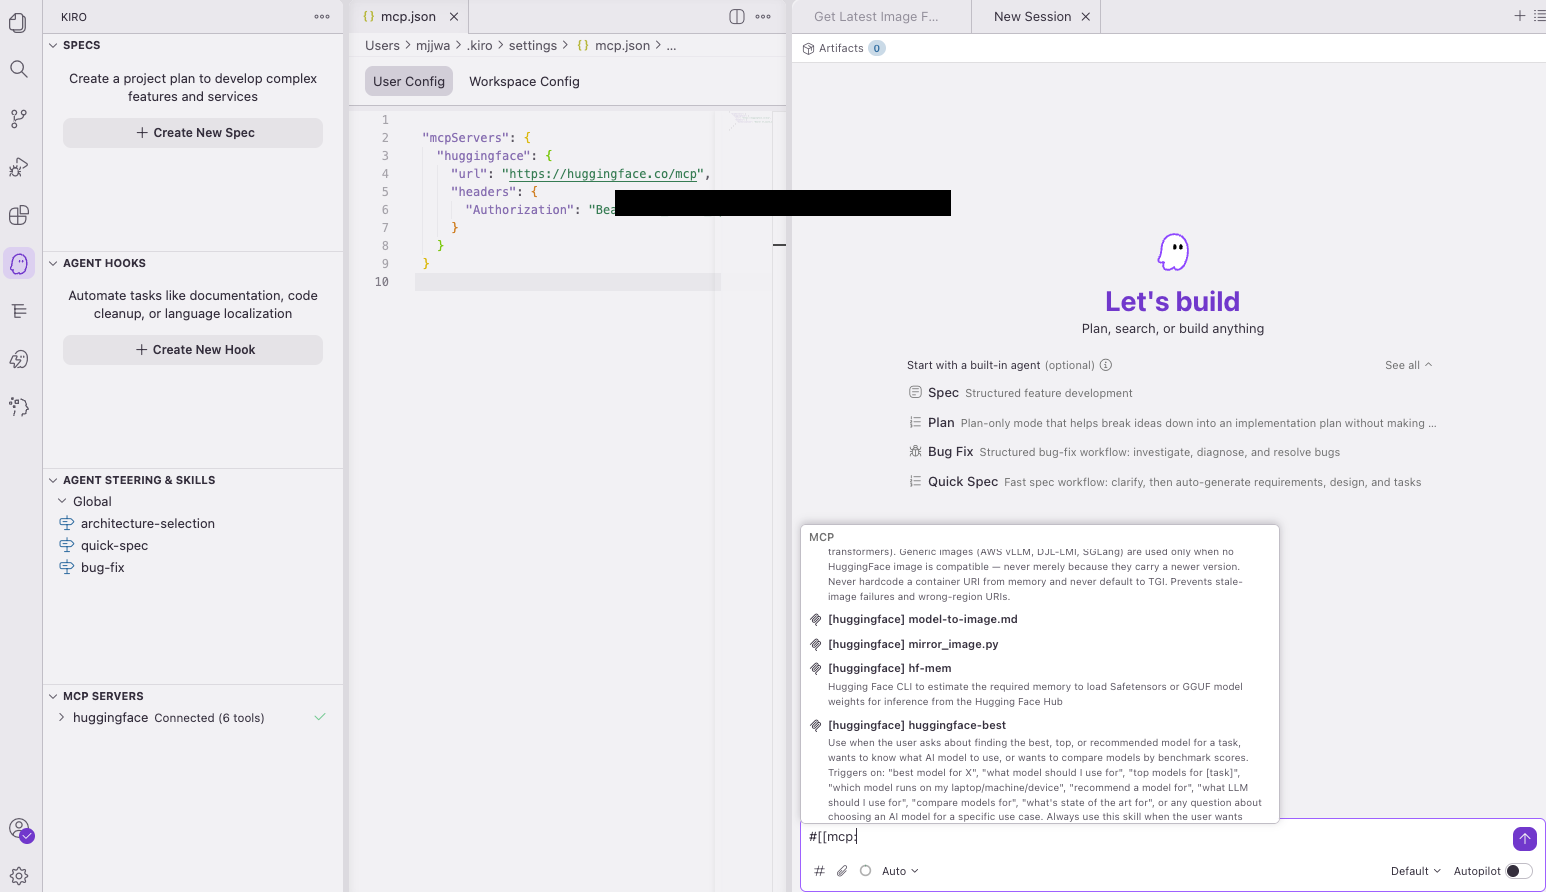

In [ ]:
# Kiro 설정(mcp.json)에 넣을 내 HF 토큰을 확인합니다
from huggingface_hub import get_token
token = get_token()
if token:
    print(token)
else:
    print("로그인 셀(데모 2)을 먼저 실행하세요.")

In [ ]:
# Kiro에 붙여넣을 첫 프롬프트
from huggingface_hub import HfApi
repo = f"{HfApi().whoami()['name']}/awskrug-demo"  # 데모 2 로그인 계정의 데이터셋
prompt = f"""Hugging Face의 dataset 레포지토리 {repo}에서 이미지를 가져와줘.
레포 URL은 https://huggingface.co/datasets/{repo} 야.
이미지는 demo 폴더 안에 있어. demo 폴더에서 가장 최근에 업로드된 이미지 파일 하나를 가져와서 보여줘.
이미지를 보여줄 때, 열어볼 수 있는 직접 링크도 함께 줘."""
print(prompt)